In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, CSVLogger, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils import class_weight
from itertools import cycle


In [ ]:
# CELL 1: CONFIGURATION & SETUP
# ==========================================
# Run this cell first to define settings and mount drive
CONFIG = {
    "DATASET_PATH": '/content/drive/MyDrive/fypdataset',
    "SAVE_DIR": '/content/drive/MyDrive/fyp_final_models',
    "CHECKPOINT_DIR": '/content/drive/MyDrive/fyp_checkpoints',
    "IMG_SIZE": (224, 224),
    "BATCH_SIZE": 32,
    "EPOCHS": 100,
    "LEARNING_RATE": 0.0001,
    "CONFIDENCE_THRESHOLD": 0.75
}

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ Google Drive Mounted")
except:
    print("⚠️ Drive mounting skipped (Run this block in Colab)")

if not os.path.exists(CONFIG["DATASET_PATH"]):
    print(f"❌ Error: Dataset not found at {CONFIG['DATASET_PATH']}.")
else:
    print(f"✅ Dataset found at {CONFIG['DATASET_PATH']}")
    classes = os.listdir(CONFIG["DATASET_PATH"])
    print(f"Detected classes: {classes}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive Mounted
✅ Dataset found at /content/drive/MyDrive/fypdataset
Detected classes: ['salmo', 'cocci', 'healthy', 'ncd']


In [ ]:
# CELL 2: DATA PREPARATION
# ==========================================
# Run this to load data and see class weights
print("\n[Part 2] Preparing Data Generators...")

preprocess_input = tf.keras.applications.efficientnet.preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    CONFIG["DATASET_PATH"],
    target_size=CONFIG["IMG_SIZE"],
    batch_size=CONFIG["BATCH_SIZE"],
    class_mode='categorical',
    subset='training',
    shuffle=True
)

validation_generator = train_datagen.flow_from_directory(
    CONFIG["DATASET_PATH"],
    target_size=CONFIG["IMG_SIZE"],
    batch_size=CONFIG["BATCH_SIZE"],
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# Calculate Class Weights
print("\n⚖️ Calculating Class Weights...")
train_classes = train_generator.classes
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_classes),
    y=train_classes
)
class_weights_dict = dict(enumerate(class_weights))

class_indices = train_generator.class_indices
labels = {v: k for k, v in class_indices.items()}

# Verification Print
print(f"\n✅ Class Indices: {class_indices}")
print(f"✅ Class Weights (Higher = More Attention):")
for i, weight in class_weights_dict.items():
    print(f"  - {labels[i]}: {weight:.4f}")



[Part 2] Preparing Data Generators...
Found 5451 images belonging to 4 classes.
Found 1361 images belonging to 4 classes.

⚖️ Calculating Class Weights...

✅ Class Indices: {'cocci': 0, 'healthy': 1, 'ncd': 2, 'salmo': 3}
✅ Class Weights (Higher = More Attention):
  - cocci: 0.8097
  - healthy: 0.8279
  - ncd: 4.5274
  - salmo: 0.7484


In [ ]:
# CELL 3: BUILD MODEL
# ==========================================
# Run this to initialize the architecture
print("\n[Part 3] Building EfficientNetB0...")

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=CONFIG["IMG_SIZE"] + (3,)
)

# Fine-tuning: Unfreeze top 20 layers
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
predictions = Dense(len(class_indices), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=Adam(learning_rate=CONFIG["LEARNING_RATE"]),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()
print("\n✅ Model Compiled Successfully")



[Part 3] Building EfficientNetB0...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 1,356,084 (5.17 MB)

 Non-trainable params: 2,698,611 (10.29 MB)


✅ Model Compiled Successfully


In [ ]:
# ==========================================
# CELL 4: TRAIN MODEL
# ==========================================
# Run this to start the long training process
print("\n[Part 4] Starting Training...")

os.makedirs(CONFIG["CHECKPOINT_DIR"], exist_ok=True)

callbacks = [
    ModelCheckpoint(
        filepath=os.path.join(CONFIG["CHECKPOINT_DIR"], "best_model.h5"),
        save_weights_only=False,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    CSVLogger(os.path.join(CONFIG["CHECKPOINT_DIR"], 'training_log.csv'))
]

history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // CONFIG["BATCH_SIZE"],
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // CONFIG["BATCH_SIZE"],
    epochs=CONFIG["EPOCHS"],
    class_weight=class_weights_dict,
    callbacks=callbacks
)



[Part 4] Starting Training...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7008 - loss: 0.8618
Epoch 1: val_accuracy improved from -inf to 0.93378, saving model to /content/drive/MyDrive/fyp_checkpoints/best_model.h5


170/170 ━━━━━━━━━━━━━━━━━━━━ 428s 2s/step - accuracy: 0.7015 - loss: 0.8602 - val_accuracy: 0.9338 - val_loss: 0.2059 - learning_rate: 1.0000e-04
Epoch 2/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 0.9062 - loss: 0.2715

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


...

170/170 ━━━━━━━━━━━━━━━━━━━━ 360s 2s/step - accuracy: 0.9665 - loss: 0.0974 - val_accuracy: 0.9754 - val_loss: 0.0831 - learning_rate: 1.0000e-04
Epoch 10/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 1.0000 - loss: 0.1232
Epoch 10: val_accuracy did not improve from 0.97545
170/170 ━━━━━━━━━━━━━━━━━━━━ 62s 366ms/step - accuracy: 1.0000 - loss: 0.1232 - val_accuracy: 0.9732 - val_loss: 0.0855 - learning_rate: 1.0000e-04
Epoch 11/100
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9753 - loss: 0.0736
Epoch 11: val_accuracy did not improve from 0.97545
170/170 ━━━━━━━━━━━━━━━━━━━━ 354s 2s/step - accuracy: 0.9753 - loss: 0.0736 - val_accuracy: 0.9740 - val_loss: 0.0760 - learning_rate: 1.0000e-04
Epoch 12/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 1.0000 - loss: 0.0219
Epoch 12: val_accuracy improved from 0.97545 to 0.97619, saving model to /content/drive/MyDrive/fyp_checkpoints/best_model.h5


170/170 ━━━━━━━━━━━━━━━━━━━━ 67s 393ms/step - accuracy: 1.0000 - loss: 0.0219 - val_accuracy: 0.9762 - val_loss: 0.0778 - learning_rate: 1.0000e-04
Epoch 13/100
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9791 - loss: 0.0623
Epoch 13: val_accuracy did not improve from 0.97619
170/170 ━━━━━━━━━━━━━━━━━━━━ 361s 2s/step - accuracy: 0.9791 - loss: 0.0623 - val_accuracy: 0.9754 - val_loss: 0.0791 - learning_rate: 1.0000e-04
Epoch 14/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 1.0000 - loss: 0.0377
Epoch 14: val_accuracy improved from 0.97619 to 0.97917, saving model to /content/drive/MyDrive/fyp_checkpoints/best_model.h5


170/170 ━━━━━━━━━━━━━━━━━━━━ 67s 395ms/step - accuracy: 1.0000 - loss: 0.0377 - val_accuracy: 0.9792 - val_loss: 0.0649 - learning_rate: 1.0000e-04
Epoch 15/100
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9752 - loss: 0.0653
Epoch 15: val_accuracy did not improve from 0.97917
170/170 ━━━━━━━━━━━━━━━━━━━━ 356s 2s/step - accuracy: 0.9752 - loss: 0.0653 - val_accuracy: 0.9725 - val_loss: 0.0770 - learning_rate: 1.0000e-04
Epoch 16/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 0.9688 - loss: 0.0431
Epoch 16: val_accuracy did not improve from 0.97917
170/170 ━━━━━━━━━━━━━━━━━━━━ 64s 381ms/step - accuracy: 0.9688 - loss: 0.0431 - val_accuracy: 0.9732 - val_loss: 0.0723 - learning_rate: 1.0000e-04
Epoch 17/100
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9779 - loss: 0.0633
Epoch 17: val_accuracy did not improve from 0.97917

Epoch 17: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
170/170 ━━━━━━━━━━━━━━━━━━━━ 360s 2s/step - accuracy: 0.9779

170/170 ━━━━━━━━━━━━━━━━━━━━ 359s 2s/step - accuracy: 0.9785 - loss: 0.0552 - val_accuracy: 0.9814 - val_loss: 0.0658 - learning_rate: 2.0000e-05
Epoch 20/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 1.0000 - loss: 0.0289
Epoch 20: val_accuracy did not improve from 0.98140

Epoch 20: ReduceLROnPlateau reducing learning rate to 3.999999898951501e-06.
170/170 ━━━━━━━━━━━━━━━━━━━━ 64s 376ms/step - accuracy: 1.0000 - loss: 0.0289 - val_accuracy: 0.9762 - val_loss: 0.0815 - learning_rate: 2.0000e-05
Epoch 21/100
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9836 - loss: 0.0495
Epoch 21: val_accuracy did not improve from 0.98140
170/170 ━━━━━━━━━━━━━━━━━━━━ 356s 2s/step - accuracy: 0.9836 - loss: 0.0495 - val_accuracy: 0.9799 - val_loss: 0.0605 - learning_rate: 4.0000e-06
Epoch 22/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 1.0000 - loss: 0.0340
Epoch 22: val_accuracy did not improve from 0.98140
170/170 ━━━━━━━━━━━━━━━━━━━━ 76s 452ms/step - accuracy: 1.0

170/170 ━━━━━━━━━━━━━━━━━━━━ 355s 2s/step - accuracy: 0.9824 - loss: 0.0445 - val_accuracy: 0.9829 - val_loss: 0.0648 - learning_rate: 4.0000e-06
Epoch 24/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 1.0000 - loss: 0.0470
Epoch 24: val_accuracy did not improve from 0.98289

Epoch 24: ReduceLROnPlateau reducing learning rate to 1e-06.
170/170 ━━━━━━━━━━━━━━━━━━━━ 63s 370ms/step - accuracy: 1.0000 - loss: 0.0470 - val_accuracy: 0.9740 - val_loss: 0.0684 - learning_rate: 4.0000e-06
Epoch 25/100
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9808 - loss: 0.0547
Epoch 25: val_accuracy did not improve from 0.98289
170/170 ━━━━━━━━━━━━━━━━━━━━ 354s 2s/step - accuracy: 0.9808 - loss: 0.0547 - val_accuracy: 0.9754 - val_loss: 0.0652 - learning_rate: 1.0000e-06
Epoch 26/100
  1/170 ━━━━━━━━━━━━━━━━━━━━ 13s 81ms/step - accuracy: 0.9688 - loss: 0.0501
Epoch 26: val_accuracy did not improve from 0.98289
170/170 ━━━━━━━━━━━━━━━━━━━━ 63s 372ms/step - accuracy: 0.9688 - loss: 0.05

In [ ]:
# CELL 5: EXPORT MODEL
# ==========================================
# Run this after training finishes to save files
print("\n[Part 5] Exporting Models...")

os.makedirs(CONFIG["SAVE_DIR"], exist_ok=True)

# Save .h5
model.save(os.path.join(CONFIG["SAVE_DIR"], "final_model.h5"))

# Save .tflite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open(os.path.join(CONFIG["SAVE_DIR"], "model_quantized.tflite"), 'wb') as f:
    f.write(tflite_model)

# Save Labels
with open(os.path.join(CONFIG["SAVE_DIR"], "labels.txt"), 'w') as f:
    sorted_labels = [k for k, v in sorted(class_indices.items(), key=lambda item: item[1])]
    for label in sorted_labels:
        f.write(label + '\n')

print(f"✅ Models saved to {CONFIG['SAVE_DIR']}")



[Part 5] Exporting Models...
Saved artifact at '/tmp/tmpvkikgehm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139936213869072: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139936213874640: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139936253852560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139936253850832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139936253850256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139936253852944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139936253851216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139936253853520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139936232032208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139936232032400: TensorSpec(shape=()


[Part 6] Generating Research Metrics...


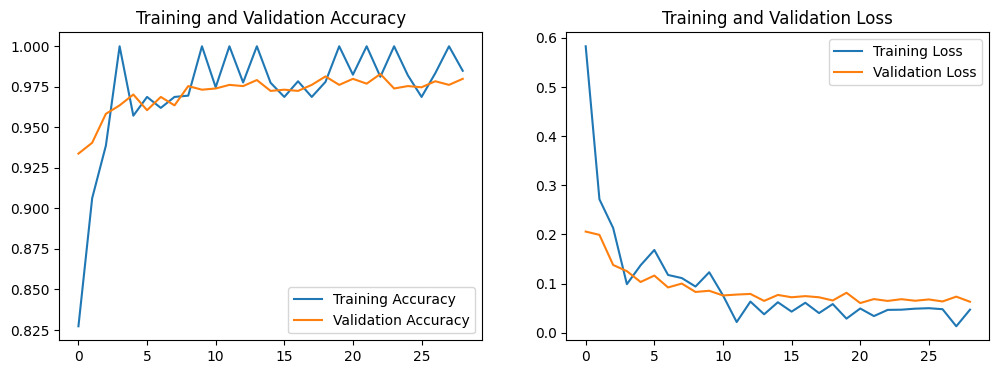

Running evaluation predictions...
43/43 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step


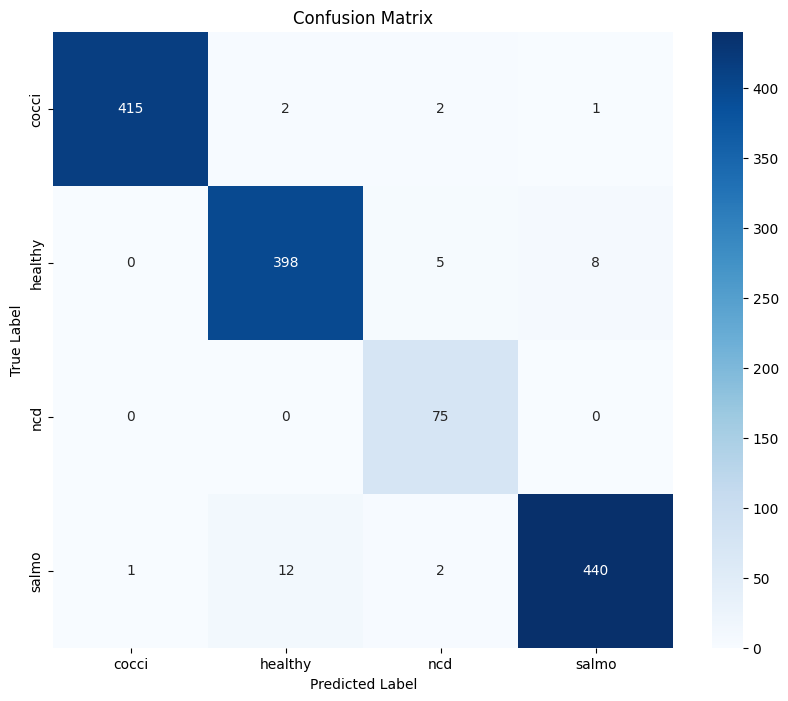


Classification Report:

              precision    recall  f1-score   support

       cocci       1.00      0.99      0.99       420
     healthy       0.97      0.97      0.97       411
         ncd       0.89      1.00      0.94        75
       salmo       0.98      0.97      0.97       455

    accuracy                           0.98      1361
   macro avg       0.96      0.98      0.97      1361
weighted avg       0.98      0.98      0.98      1361



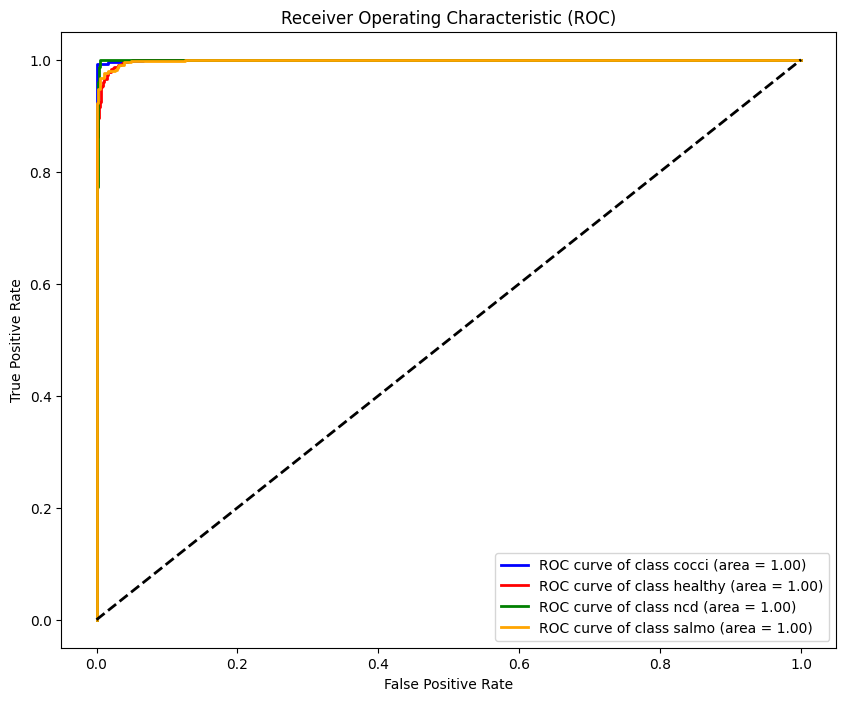


🎉 Evaluation Complete. Check /content/drive/MyDrive/fyp_final_models/metrics for saved plots.


In [ ]:
# CELL 6: EVALUATION & PLOTS
# ==========================================
# Run this to see graphs and metrics
print("\n[Part 6] Generating Research Metrics...")

metrics_dir = os.path.join(CONFIG["SAVE_DIR"], "metrics")
os.makedirs(metrics_dir, exist_ok=True)
class_names = list(class_indices.keys())

# 1. Plot Training History
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.savefig(os.path.join(metrics_dir, 'training_curves.png'))
plt.show()

# 2. Confusion Matrix
print("Running evaluation predictions...")
validation_generator.reset()
Y_pred = model.predict(validation_generator)
y_pred_classes = np.argmax(Y_pred, axis=1)
y_true = validation_generator.classes

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig(os.path.join(metrics_dir, 'confusion_matrix.png'))
plt.show()

# 3. Classification Report
report = classification_report(y_true, y_pred_classes, target_names=class_names)
print("\nClassification Report:\n")
print(report)
with open(os.path.join(metrics_dir, 'classification_report.txt'), 'w') as f:
    f.write(report)

# 4. ROC Curve
y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
n_classes = y_true_bin.shape[1]
fpr, tpr, roc_auc = dict(), dict(), dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], Y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
colors = cycle(['blue', 'red', 'green', 'orange', 'purple'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'.format(class_names[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.savefig(os.path.join(metrics_dir, 'roc_curve.png'))
plt.show()

print(f"\n🎉 Evaluation Complete. Check {metrics_dir} for saved plots.")